# Logistic Regression on the Breast Cancer Dataset

This notebook walks through the same simple logistic regression model from
`bcancer.py`, one small step at a time, with prints and plots along the way
so you can see what's happening at each stage — including why logistic
regression is often drawn as an "S-curve" (the sigmoid function).

Steps:
1. Imports
2. Load & explore the data
3. Peek at one feature visually
4. Train/test split
5. Fit the model
6. Evaluate it
7. Which features mattered most?
8. The sigmoid / S-curve

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

## 2. Load & explore the data

scikit-learn ships this dataset built in, so there's nothing to download.
Each row is a tumor; each column is a measurement taken from a digitized
image (radius, texture, smoothness, etc.). The target is `0` (malignant) or
`1` (benign).

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Classes:", list(data.target_names))
print("Class balance:")
for class_index, class_name in enumerate(data.target_names):
    print(f"  {class_name}: {(y == class_index).sum()}")

Samples: 569
Features: 30
Classes: [np.str_('malignant'), np.str_('benign')]
Class balance:
  malignant: 212
  benign: 357


## 3. Peek at one feature visually

Before fitting anything, it helps to see *why* a feature might be
predictive. Here's `mean radius` split by diagnosis — malignant tumors tend
to be larger.

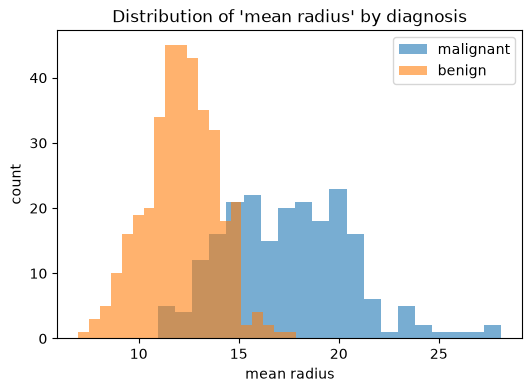

In [3]:
feature_name = "mean radius"
feature_index = list(data.feature_names).index(feature_name)
feature_values = X[:, feature_index]

plt.figure(figsize=(6, 4))
plt.hist(feature_values[y == 0], bins=20, alpha=0.6, label="malignant")
plt.hist(feature_values[y == 1], bins=20, alpha=0.6, label="benign")
plt.xlabel(feature_name)
plt.ylabel("count")
plt.title(f"Distribution of '{feature_name}' by diagnosis")
plt.legend()
plt.show()

## 4. Train/test split

Same as the plain script: hold out some data to check the model on
examples it hasn't seen.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Train samples: 426
Test samples: 143


## 5. Fit the model

This is the exact same `LogisticRegression` call as in `bcancer.py`.

In [5]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

print("Model fit with", model.coef_.shape[1], "feature coefficients")

Model fit with 30 feature coefficients


## 6. Evaluate it

Accuracy on the held-out test set, plus a confusion matrix so we can see
*what kind* of mistakes (if any) the model makes.

Accuracy: 0.951048951048951


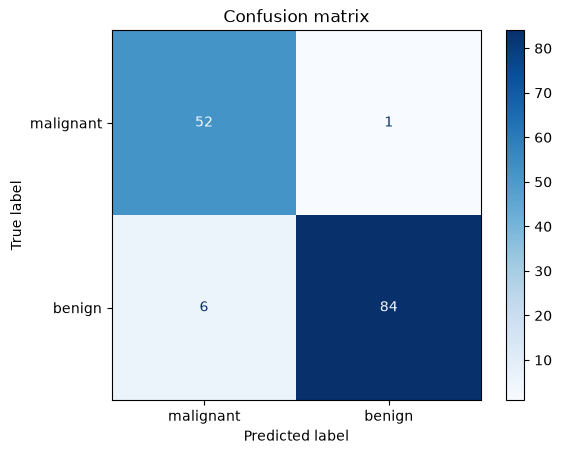

In [6]:
accuracy = model.score(X_test, y_test)
print("Accuracy:", accuracy)

ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test, display_labels=data.target_names, cmap="Blues"
)
plt.title("Confusion matrix")
plt.show()

## 7. Which features mattered most?

Logistic regression learns one coefficient per feature. Larger magnitude
(either sign) means that feature moves the prediction more.

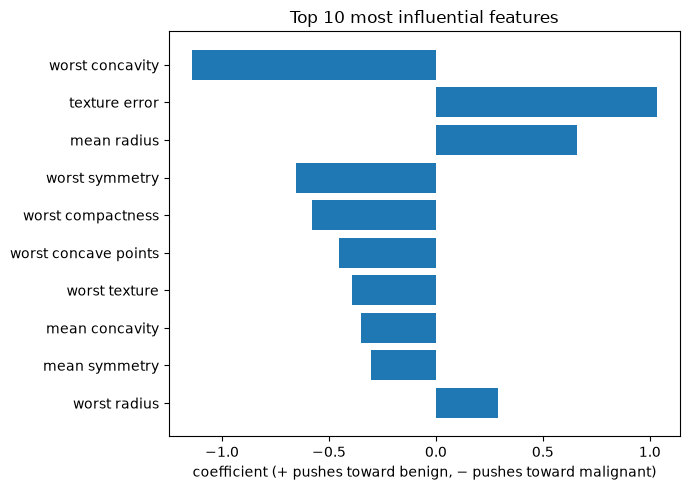

In [7]:
coefficients = model.coef_[0]
top_10 = np.argsort(np.abs(coefficients))[::-1][:10]

plt.figure(figsize=(7, 5))
plt.barh([data.feature_names[i] for i in top_10][::-1], coefficients[top_10][::-1])
plt.xlabel("coefficient (+ pushes toward benign, − pushes toward malignant)")
plt.title("Top 10 most influential features")
plt.tight_layout()
plt.show()

## 8. The sigmoid / S-curve

Logistic regression doesn't predict 0/1 directly. It computes a raw score
(`decision_function`) and squashes it through the **sigmoid function**,
$\sigma(z) = \dfrac{1}{1 + e^{-z}}$, to get a probability between 0 and 1.

Plotting every test prediction's probability against its raw score shows
that they all land exactly on that S-shaped curve.

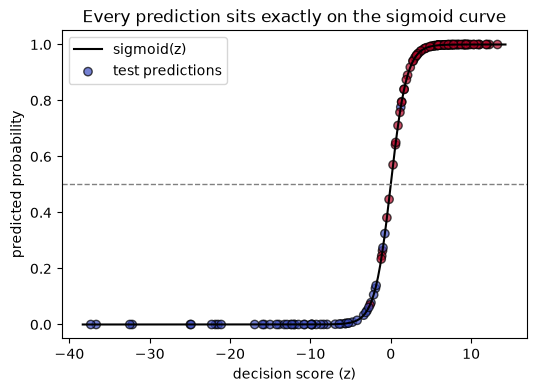

In [8]:
decision_scores = model.decision_function(X_test)
predicted_probabilities = model.predict_proba(X_test)[:, 1]

z = np.linspace(decision_scores.min() - 1, decision_scores.max() + 1, 200)
sigmoid_curve = 1 / (1 + np.exp(-z))

plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid_curve, color="black", label="sigmoid(z)")
plt.scatter(
    decision_scores, predicted_probabilities,
    c=y_test, cmap="coolwarm", edgecolor="k", alpha=0.7, label="test predictions"
)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel("decision score (z)")
plt.ylabel("predicted probability")
plt.title("Every prediction sits exactly on the sigmoid curve")
plt.legend()
plt.show()

### A classic single-feature S-curve: `mean radius`

The plot above is always a perfect sigmoid by definition. To see the
textbook picture — real data points scattered at 0 and 1 with an S-curve
fit through them — let's fit a second, throwaway logistic regression using
just `mean radius` (tumor size is the most intuitive single predictor here).

*Why not seaborn?* `sns.regplot(..., logistic=True)` draws this exact kind
of curve in one line, but it needs `statsmodels` (and pulls in `pandas`)
just for the fit. Since we already have a fitted `LogisticRegression`
approach from scikit-learn, plain matplotlib gets the same picture without
extra dependencies — and it's fast enough to repeat for every feature,
which we'll do right after this.

Most correlated single feature: 'worst concave points' (r=-0.79)


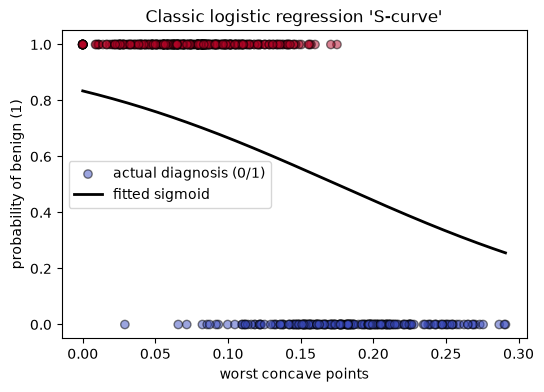

In [9]:
correlations = np.array([np.corrcoef(X[:, i], y)[0, 1] for i in range(X.shape[1])])
best_feature_index = np.argmax(np.abs(correlations))
best_feature_name = data.feature_names[best_feature_index]
print(f"Most correlated single feature: '{best_feature_name}' (r={correlations[best_feature_index]:.2f})")

single_feature = X[:, [best_feature_index]]
single_model = LogisticRegression()
single_model.fit(single_feature, y)

x_range = np.linspace(single_feature.min(), single_feature.max(), 200).reshape(-1, 1)
curve = single_model.predict_proba(x_range)[:, 1]

plt.figure(figsize=(6, 4))
plt.scatter(single_feature, y, c=y, cmap="coolwarm", edgecolor="k", alpha=0.5, label="actual diagnosis (0/1)")
plt.plot(x_range, curve, color="black", linewidth=2, label="fitted sigmoid")
plt.xlabel(best_feature_name)
plt.ylabel("probability of benign (1)")
plt.title("Classic logistic regression 'S-curve'")
plt.legend()
plt.show()

## Wrap-up

- Loaded a built-in dataset, no downloads needed.
- Split it into train/test sets.
- Fit the same simple `LogisticRegression` model as `bcancer.py`.
- Checked accuracy and saw a confusion matrix.
- Looked at which features mattered most.
- Saw exactly why logistic regression is drawn as an S-curve, both in
  general (the sigmoid function) and with real single-feature data.